# Combine structured effects with a neural remainder

A structured spline predictor and a neural network can explain the same variation. Adding them without identification makes the allocation arbitrary even when their sum predicts well. This example fits their sum while projecting the neural representation out of the structured training design.

The response has a smooth x effect and an x-by-z interaction. We supply a structured smooth plus a linear z term, and let the neural remainder use both source features. The decomposition is relative to that chosen structured design and the training cohort; it is not a causal decomposition.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from nampy import SemiStructuredRegressor, SemiStructuredTrainingConfig
from nampy.neural.configs import DefaultSemiStructuredConfig


In [2]:
def show_figure(figure, name):
    # name is a stable identifier for the corresponding guide figure.
    plt.show()
    plt.close(figure)

In [3]:
rng = np.random.default_rng(67)
X = pd.DataFrame({"x": rng.uniform(-1, 1, 240), "z": rng.uniform(-1, 1, 240)})
y = 0.5 + np.sin(3 * X.x.to_numpy()) + 1.3 * X.x.to_numpy() * X.z.to_numpy()
y += rng.normal(0, 0.1, len(X))
train, validation, test = np.arange(160), np.arange(160, 200), np.arange(200, 240)

## Fit jointly using training and validation cohorts

Keep 160 training, 40 validation and 40 final test rows. The neural representation is orthogonalized against the full structured training matrix before it contributes to the joint predictor. The structured coefficients and neural representation are optimized jointly, with the spline smoothing parameter fixed at 0.2. Validation selects the retained epoch.

If B is the structured training design and H the learned representation, the remainder uses H minus its projection onto B. Without this restriction, a structured column could be moved into the neural part without changing the total prediction. Orthogonality removes that ambiguity within the declared training design; it does not make the model's interpretation invariant to changing that design.

In [4]:
architecture = DefaultSemiStructuredConfig(
    structured_formula="~s(x,k=5)+z", neural_features=("x", "z"),
    hidden_dims=(12,), representation_dim=5,
)
model = SemiStructuredRegressor(
    architecture_config=architecture,
    training=SemiStructuredTrainingConfig(
        epochs=120, lr=0.025, patience=25, smoothing_params=[0.2], random_state=18,
    ),
).fit(X.iloc[train], y[train], X_val=X.iloc[validation], y_val=y[validation])

## Predict unseen feature combinations

The plotted grid is a new x sweep with z held at 0.8. The fitted training projection is reused for these rows; recomputing it on the grid would change the decomposition. The optional checks below verify reconstruction and singleton-versus-batch prediction behavior.

In [5]:
grid = pd.DataFrame({"x": np.linspace(-1, 1, 120), "z": np.full(120, 0.8)})
components = model.predict_components(grid)
neural = components.terms["neural_component"][:, 0]
structured = components.link[:, 0] - neural

## Read the decomposition on a fixed-z slice

The blue curve is the structured predictor including its intercept; the orange curve is the projected neural contribution, and their sum is the purple total. On this slice the neural remainder ranges from about -0.93 to 0.80 and changes the total substantially. The dashed true mean also exposes imperfect recovery near the edges; an identifiable decomposition is not a guarantee of perfect fit.

Orthogonality holds over the training design, so a conditional slice can still show a visible trend in the remainder. The remainder is a multivariate contribution, rather than an additional main effect of x.

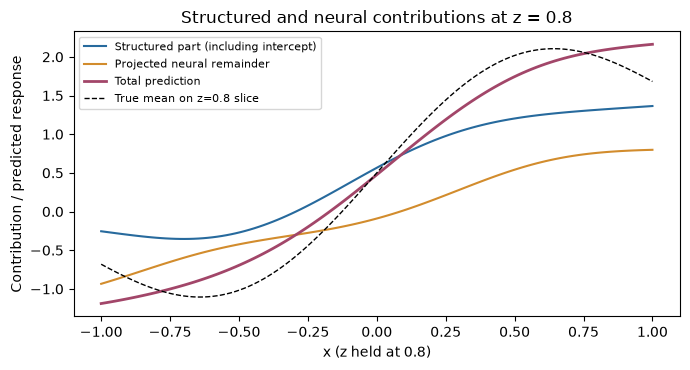

In [6]:
figure, axis = plt.subplots(figsize=(7, 3.8))
axis.plot(grid.x, structured, color="#276A9D", label="Structured part (including intercept)")
axis.plot(grid.x, neural, color="#D28C2D", label="Projected neural remainder")
axis.plot(grid.x, components.link[:, 0], color="#A24669", lw=2, label="Total prediction")
axis.plot(grid.x, 0.5 + np.sin(3 * grid.x) + 1.3 * grid.x * grid.z,
          "k--", lw=1, label="True mean on z=0.8 slice")
axis.set(xlabel="x (z held at 0.8)", ylabel="Contribution / predicted response",
          title="Structured and neural contributions at z = 0.8")
axis.legend(fontsize=8)
figure.tight_layout()
show_figure(figure, "semistructured_components")

In [7]:
components.validate_additive_reconstruction()
np.testing.assert_allclose(
    model.predict(grid.iloc[:1]), model.predict(grid)[:1], atol=1e-12
)
assert model.orthogonality_error_ < 1e-10

## Assess held-out prediction

The held-out RMSE is 0.282. Along the illustrated slice, the neural contribution ranges from approximately -0.93 to 0.80. The total prediction follows the main pattern but still misses part of the true mean near the boundaries.

The chosen structured function space defines the interpretation of the two contributions. The remainder is not evidence for a unique scientific mechanism or a causal effect.

In [8]:
test_rmse = np.sqrt(np.mean((model.predict(X.iloc[test]).ravel() - y[test]) ** 2))
print(f"Held-out RMSE: {test_rmse:.3f}.")
print(f"Neural contribution along this slice: {neural.min():.2f} to {neural.max():.2f}.")

Held-out RMSE: 0.282.
Neural contribution along this slice: -0.93 to 0.80.


## Extend the analysis deliberately

Inspect held-out residuals before enlarging the network. Change the structured formula when the scientific interpretation requires a different protected function space, then refit the projection and reassess the model. See [semi-structured models](../user_guide/semistructured.rst) for the fitting and persistence contracts.